# Notebook 2 -- Feature Extraction

**Purpose:** Extract raster-derived features for each drop polygon side. Covers four parts:

- **Part 1:** DOB (Day of Burning) local buffer -- when pixels burned relative to drop date
- **Part 2:** LANDFIRE FBFM13 fuel model (local buffer) -- what fuel type was present
- **Part 3:** Raster split -- whole-fire burn comparison across an extended drop line (biggest accuracy driver)
- **Part 4:** Additional feature engineering explored after the error-analysis meeting with the professor, aimed at pushing past ~90% toward the 95-96% target (distance to unburned, pre-drop pixels, expanded polygon, fire-start angle, fuel/MTBS on expanded polygon, DEM)

**Input:** `drops_clean.geojson` (from Notebook 1)

**Key outputs:**
- `training_features_dob.csv`
- `training_features_fuel.csv`
- `training_features_split.csv`
- `training_features_dist.csv`
- `training_features_predrop.csv`
- `training_features_expanded.csv`
- `training_features_fuel_expanded.csv`

In [1]:
# ---- Imports ----
import geopandas as gpd
import rasterio
import os
import numpy as np
import pandas as pd
from rasterio.mask import mask
from scipy import stats as scipy_stats
import matplotlib.pyplot as plt
import rasterio.plot


In [2]:
# Loading clean drops that were saved in Notebook 1. 
drops = gpd.read_file("drops_clean.geojson")
print(f"Loaded {len(drops)} drop sides across {drops['Evnt_ID'].nunique()} fires")

Loaded 21234 drop sides across 424 fires


# Part 1: DOB Feature Extraction

For each drop side polygon, we sample the DOB raster underneath it and compute burn-day statistics relative to the drop date (converted to day-of-year)

**Key features extracted:**
- `mean_dob`/`median_dob` -- average burn day across all burned pixels
- `early_pixels` - pixels that burned BEFORE the drop (fire origin signal)
- `late_pixels` -- pixels that burned AFTER the drop (protected side signal)
- `unburned_pixels` -- pixels that never burned (protected side signal)
- `burned_pixels`/`total_pixels` -- overall burn coverage

In [3]:
# Open the tif file of the fire and extract pixels under the drop polygon. 
def extract_pixel_stats(geometry, tif_path, drop_doy, nodata_val=65535):
    try:
        with rasterio.open(tif_path) as src:
            #crop=True will prevent from loading the whole raster but only the polygon under the drop. 
            #filled=True will make sure that the pixels inside the bounding box but outside the drop polygon are set to nodata, so that only the pixels inside the polygon are counted as valid burn-day values. 
            # nodata_val=65535 - this variable represents the pixels which never burnt. 
            out_image, _ = mask(src, [geometry], crop=True, filled=True, nodata=nodata_val)

            #usually returns (band, cols, rows). since it is 2d, we will take [0]

            pixels = out_image[0]

    except Exception as e:
        return None
    


    # filter out pixels that burned. valid is a 1D array that has the doy of the burns. 
    valid = pixels[pixels != nodata_val]



    # This is for the edge cases where no pixels under the polygons burned. return NaN for DOB stats and 0 for all pixels counts. unburned_pixels and total_pixels are still meaningful. 
    if len(valid) == 0:
        return {
            "mean_dob" : np.nan, "median_dob":np.nan, 
            "early_pixels": 0, "late_pixels":0,
            "unburned_pixels": int(np.sum(pixels == nodata_val)), 
            "total_pixels" : int(pixels.size), "burned_pixels":0
        }
    

    # Normal case where at least some pixels under the drop burned. 
    return {
        # average and median burn day across all pixels. 
        "mean_dob": float(np.mean(valid)), 
        "median_dob": float(np.median(valid)),

        # pixels that burned before the drop date. Fire was already here (origin side)
        "early_pixels": int(np.sum(valid < drop_doy)),

        # pixels that burned after the drop date. Fire arrived here later. (protected side)
        "late_pixels": int(np.sum(valid > drop_doy)),
        
        # pixels that never burned at all
        "unburned_pixels" : int(np.sum(pixels == nodata_val)),

        #total pixels in the cropped bounding box (burned+unburned+boundary)
        "total_pixels": int(pixels.size),

        # total burned pixels 
        "burned_pixels": int(len(valid))
    }

In [4]:
# Feature Extraction Loop 
# Iterates over every drop-side row in the shapefile. 
# For each row, samples the DOB raster pixels under that polygon and computes burn-day statistics relative to the burn date. 
# Results are collected in a list of dicts, one per drop side, which is later converted into the training DataFrame. 

rows = [] # Stores one dict per successfully processed drop-side. 
skipped = 0 # tracks rows where extraction failed. 

for idx, drop in drops.iterrows():

    # Extract pixel statistics from the DOB raster under this drop-side polygon. Returns None if any error occurs. 
    stats = extract_pixel_stats(
        geometry=drop.geometry, # polygon shape of the drop side.
        tif_path = drop["tif_path"], # path to this fire's DOB raster
        drop_doy = drop["drop_doy"], # drop date as day-of-year for early/late pixel comparison. 

    )


    # skip this row if extraction failed and count it. 
    if stats is None:
        skipped += 1
        continue


    # Attach identifying and operational metadata from the shapefile row to the raster-derived stats, so each row in the final DataFrame contains both feature values and bookkeeping information. 

    stats.update({
        "event_id": drop["Evnt_ID"], # fire incident ID. Later used for GroupKFold splitting. 
        "buff_id": drop["buff_id"], # which side of the drop (1 or 2)
        "altitude": drop.get("altitude", np.nan), # aircraft altitude at the time of drop
        "knots": drop.get("Knots1", np.nan), # aircraft speed at the time of drop
        "gallons": drop.get("Gallns1", np.nan), # volume of retardants dropped
        "drop_seconds": drop.get("DrpScnd", np.nan), # duration of drop in seconds
        "pt": drop["new_pt"], # target variable : 1 = protected side, 0 = origin side. 
        "drop_id" : drop["drop_id"] # unique drop identifier (event_id + lat + long + utcdate) - used to pair two sides of the same drop. 
    })

    rows.append(stats)


# BUILDING THE DATAFRAME

print(f"Processed: {len(rows)}, Skipped: {skipped}")

# Convert list of dicts to DataFrame - one row per drop-side
df_dob = pd.DataFrame(rows)

# Saving the file to CSV so features don't need to be extracted every time. 
df_dob.to_csv("training_features_dob.csv", index=False)
print(df_dob.head())

Processed: 21081, Skipped: 153
   mean_dob  median_dob  early_pixels  late_pixels  unburned_pixels  \
0     165.0       165.0             0            0               66   
1     165.0       165.0             0            0               67   
2     165.0       165.0             0            0              123   
3     165.0       165.0             0            0              212   
4     165.0       165.0             0            0              173   

   total_pixels  burned_pixels               event_id  buff_id  altitude  \
0           180            114  AZ3143311069520170614      1.0       NaN   
1           180            113  AZ3143311069520170614      2.0       NaN   
2           252            129  AZ3143311069520170614      1.0       NaN   
3           247             35  AZ3143311069520170614      2.0       NaN   
4           240             67  AZ3143311069520170614      1.0       NaN   

   knots  gallons drop_seconds  pt  \
0  165.0      0.0           53   1   
1  165.0 

In [5]:
# Running some sanity check to see if our training data shows real signal and the extracted features actually differ between the two classes (protected vs origin)

# If features carry a real signal, pt=1 (protected) should show: 
# - more unburned pixels (protected side less likely to have burned)
# - fewer early pixels (less fire activity before the drop on the protected side)
# - fewer burned pixels (less total fire)


# If the means look nearly identical between pt=0 and pt=1, the features have no discriminative power and model won't learn anything useful. 

df_dob.groupby("pt")[["unburned_pixels", "early_pixels", "late_pixels", "burned_pixels"]].mean()

,unburned_pixels,early_pixels,late_pixels,burned_pixels
pt,,,,
0,181.323516,16.049967,22.596594,89.845394
1,211.656878,4.444232,21.860149,49.332504


In [7]:
# Result confirmed the hypothesis. 
# We can see a clear separation between pt=0 and pt=1, especially in early_pixels. 

In [6]:
# Second Sanity Check
# Each drop should have exactly 2 rows - one per side (buff_id 1 and 2)
# This check verifies that our drop_id construction above correctly groups rows into pairs. 
# Expected result: almost all drop_ids should have exactly two rows. 
print(df_dob.groupby("drop_id").size().value_counts())

2    10239
1      152
4      109
6        2
3        1
Name: count, dtype: int64


---
## Part 2: LANDFIRE Fuel Feature Extraction

**Source:** LANDFIRE 2022 Anderson Fire Behavior Fuel Model (FBFM13) CONUS  
**Reference:** Anderson, H.E. (1982). *Aids to determining fuel models for estimating fire behavior.* USDA Forest Service, General Technical Report INT-122.  
**Data Dictionary:** https://landfire.gov/sites/default/files/DataDictionary/LF2023/LF23_F13ADD_240.pdf

**Fuel Code Reference:**

| Value | Code | Category | Description |
|-------|------|----------|-------------|
| 1-3 | FBFM1-3 | Grass | Fast spreading, lower intensity |
| 4-7 | FBFM4-7 | Shrub | Moderate spread |
| 8-10 | FBFM8-10 | Timber | Slower spread, higher intensity |
| 11-13 | FBFM11-13 | Slash | High intensity, difficult to control |
| 91-99 | — | Non-burnable | Urban, water, barren etc. |
| -9999 | — | NoData | Fill / no data |

**Note:** LANDFIRE 2022 data is used as a proxy for 2017-2019 fuel conditions.
Broad fuel model classifications (grass, shrub, timber) are generally stable over multi-year periods.

## Category Groupings Used In Feature Extraction

```python
grass_codes       = [1, 2, 3]         # fast spreading, lower intensity
shrub_codes       = [4, 5, 6, 7]      # moderate spread
timber_codes      = [8, 9, 10]        # slower spread, higher intensity
slash_codes       = [11, 12, 13]      # high intensity, difficult to control
nonburnable_codes = [91, 92, 93, 98, 99]  # non-burnable surfaces
```

In [ ]:
# Feature extraction
# We will extract pixels under each drop polygon and create new features per polygon. 

from scipy import stats as scipy_stats


fuel_rows = []
skipped = 0

# opening the raster once since it is huge. 
with rasterio.open("training_data/LANDFIRE_fuel/tiff/LC22_F13_220.tif") as src:

    for idx, drop in drops.iterrows():

        # cut out pixels under this polygon
        try:
            out_image, _ = mask(src, [drop.geometry],
                                crop=True, filled=True, nodata=32767)
            pixels = out_image[0]
        except Exception:
            skipped += 1
            continue

        # remove nodata pixels
        valid = pixels[(pixels != 32767) & (pixels != -9999)]

        if len(valid) == 0:
            stats = {
                "dominant_fuel":     np.nan,
                "fuel_diversity":    0,
                "grass_pixels":      0,
                "shrub_pixels":      0,
                "timber_pixels":     0,
                "slash_pixels":      0,
                "nonburnable_pixels": 0,
                "total_fuel_pixels": 0
            }
        else:
            stats = {
                # most common fuel type under this polygon
                "dominant_fuel": int(scipy_stats.mode(valid, keepdims=True).mode[0]),

                # how many different fuel types present
                "fuel_diversity": int(len(np.unique(valid))),

                # count pixels by fuel category
                "grass_pixels":       int(np.sum(np.isin(valid, [1, 2, 3]))),
                "shrub_pixels":       int(np.sum(np.isin(valid, [4, 5, 6, 7]))),
                "timber_pixels":      int(np.sum(np.isin(valid, [8, 9, 10]))),
                "slash_pixels":       int(np.sum(np.isin(valid, [11, 12, 13]))),
                "nonburnable_pixels": int(np.sum(np.isin(valid, [91, 92, 93, 98, 99]))),
                "total_fuel_pixels":  int(len(valid))
            }

        # attaching identifiers so we can merge this new df to the original features
        stats.update({
            "event_id": drop["Evnt_ID"],
            "buff_id":  drop["buff_id"],
            "drop_id":  drop["drop_id"]
        })
        fuel_rows.append(stats)

print(f"Processed: {len(fuel_rows)}, Skipped: {skipped}")
df_fuel = pd.DataFrame(fuel_rows)
df_fuel.to_csv("training_features_fuel.csv", index=False)
print(df_fuel.head())

Processed: 21234, Skipped: 0
   dominant_fuel  fuel_diversity  grass_pixels  shrub_pixels  timber_pixels  \
0              5               3            36           108              0   
1              5               4            35           100              2   
2              5               3            36            98              0   
3              2               3            81            53              0   
4              5               3            52            76              1   

   slash_pixels  nonburnable_pixels  total_fuel_pixels               event_id  \
0             0                   0                144  AZ3143311069520170614   
1             0                   0                137  AZ3143311069520170614   
2             0                   0                134  AZ3143311069520170614   
3             0                   0                134  AZ3143311069520170614   
4             0                   0                129  AZ3143311069520170614   

   buff_i

# Part 3: Raster Split Feature Extraction

**Motivation**: DOB features sampled only within the small buffered drop polygon showed limited signal -- many drops had nearly identical burn statistics on both sides, and the best DOB-only model plateaued to around 81% accuracy. 


**Approach**: Instead of sampling only the small buffer polygon, extend the drop line across the entire fire's DOB raster and split the whole raster into two halves. Compute pixel statistics on each half (thousands of pixels)

**Hypothesis**: The side with more burned pixel (relative to the whole fire, not just the local buffer) is more likely to be the fire origin side; the side with fewer burned pixels is more likely to be the protected side. 

**Validated visually in QGIS** across multiple random drops before implementation --  the patten held consistently. 

**Result**: This became the single largest driver of model improvement, taking the combined model from ~81% to ~90% accuracy (see Notebook 3). 



In [8]:
# Extend Drop Line Function
from shapely.ops import split as shapely_split, linemerge
from shapely.geometry import LineString, box

def extend_line(line, distance=500000):
    """
    Extend a LineString in both directions far beyond raster bounds
    (distance=500km ensures the line cuts through any CONUS fire raster).
    Handles MultiLineString by merging into a single line first.
    """
    # handle MultiLineString — merge into single LineString
    if line.geom_type == "MultiLineString":
        line = linemerge(line)
        # if merge still gives MultiLineString, take the longest segment
        if line.geom_type == "MultiLineString":
            line = max(line.geoms, key=lambda g: g.length)

    coords = list(line.coords)
    start = np.array(coords[0])
    end = np.array(coords[-1])

    # unit direction vector of the line
    direction = end - start
    direction = direction / np.linalg.norm(direction)

    # extend both endpoints far beyond raster bounds
    new_start = start - direction * distance
    new_end = end + direction * distance

    return LineString([new_start, new_end])

In [9]:
# Split Extraction Function

def extract_split_features(pair, tif_path, nodata_val=65535):
    """
    Split the DOB raster by the drop line and extract pixel stats
    for each half, matched to the correct buff_id.

    pair: GeoDataFrame with exactly 2 rows (both sides of one drop)
    tif_path: path to the fire's DOB raster

    Returns (stats_side1, stats_side2) or None if extraction fails.
    """
    row_1 = pair[pair["buff_id"] == 1].iloc[0]
    row_2 = pair[pair["buff_id"] == 2].iloc[0]
    geom_1 = row_1.geometry
    geom_2 = row_2.geometry

    # get shared boundary between the two polygons = the drop line
    drop_line = geom_1.intersection(geom_2)

    # guard: skip if no shared boundary
    if drop_line.is_empty:
        return None

    # guard: handle GeometryCollection by extracting line components
    if drop_line.geom_type == "GeometryCollection":
        lines = [g for g in drop_line.geoms if "Line" in g.geom_type]
        if not lines:
            return None
        drop_line = linemerge(lines)

    # guard: must be a line geometry at this point
    if drop_line.geom_type not in ["LineString", "MultiLineString"]:
        return None

    # extend the line far beyond the raster bounds
    extended = extend_line(drop_line)

    with rasterio.open(tif_path) as src:
        bounds = src.bounds
        raster_bbox = box(bounds.left, bounds.bottom, bounds.right, bounds.top)

        # split the raster's bounding box into two halves using the extended line
        try:
            result = shapely_split(raster_bbox, extended)
            if len(result.geoms) != 2:
                return None
            half_A, half_B = result.geoms
        except Exception:
            return None

        # match halves to buff_ids using polygon centroids
        # (the split doesn't know which half is 'side 1' vs 'side 2')
        centroid_1 = geom_1.centroid
        if half_A.contains(centroid_1):
            side1_geom, side2_geom = half_A, half_B
        else:
            side1_geom, side2_geom = half_B, half_A

        # sample pixels for each side
        try:
            img_1, _ = mask(src, [side1_geom], crop=True, filled=True, nodata=nodata_val)
            img_2, _ = mask(src, [side2_geom], crop=True, filled=True, nodata=nodata_val)
        except Exception:
            return None

    pixels_1 = img_1[0]
    pixels_2 = img_2[0]

    def compute_stats(pixels, drop_doy, nodata_val):
        valid = pixels[pixels != nodata_val]
        if len(valid) == 0:
            return {
                "split_mean_dob": np.nan,
                "split_early_pixels": 0,
                "split_late_pixels": 0,
                "split_unburned_pixels": int(np.sum(pixels == nodata_val)),
                "split_burned_pixels": 0,
                "split_total_pixels": int(pixels.size)
            }
        return {
            "split_mean_dob":        float(np.mean(valid)),
            "split_early_pixels":    int(np.sum(valid < drop_doy)),
            "split_late_pixels":     int(np.sum(valid > drop_doy)),
            "split_unburned_pixels": int(np.sum(pixels == nodata_val)),
            "split_burned_pixels":   int(len(valid)),
            "split_total_pixels":    int(pixels.size)
        }

    stats_1 = compute_stats(pixels_1, row_1["drop_doy"], nodata_val)
    stats_2 = compute_stats(pixels_2, row_2["drop_doy"], nodata_val)

    stats_1.update({"event_id": row_1["Evnt_ID"], "buff_id": 1, "drop_id": row_1["drop_id"]})
    stats_2.update({"event_id": row_2["Evnt_ID"], "buff_id": 2, "drop_id": row_2["drop_id"]})

    return stats_1, stats_2

In [10]:
# Split Extraction Loop
# Process one drop pair at a time (need both sides to construct the drop line)

split_rows = []
skipped_split = 0

drop_pairs = drops.groupby("drop_id")

for drop_id, pair in drop_pairs:
    # only process clean pairs (exactly 2 sides, both buff_ids present)
    if len(pair) != 2:
        skipped_split += 1
        continue
    if set(pair["buff_id"].astype(int)) != {1, 2}:
        skipped_split += 1
        continue

    tif_path = pair.iloc[0]["tif_path"]
    result = extract_split_features(pair, tif_path)

    if result is None:
        skipped_split += 1
        continue

    stats_1, stats_2 = result
    split_rows.append(stats_1)
    split_rows.append(stats_2)

print(f"Processed: {len(split_rows)} rows ({len(split_rows)//2} drop pairs)")
print(f"Skipped: {skipped_split}")

df_split = pd.DataFrame(split_rows)
df_split.to_csv("training_features_split.csv", index=False)
print(df_split.head())

Processed: 20720 rows (10360 drop pairs)
Skipped: 162
   split_mean_dob  split_early_pixels  split_late_pixels  \
0      165.237059                   0                316   
1      165.031311                   0                288   
2      165.057838                   0                604   
3      165.000000                   0                  0   
4      165.000000                2182                  0   

   split_unburned_pixels  split_burned_pixels  split_total_pixels  \
0                   2561                 1333                3894   
1                   6201                 9198               15399   
2                   7434                10443               17877   
3                   1212                   88                1300   
4                  10031                 2182               12213   

                event_id  buff_id  \
0  AZ3143311069520170614        1   
1  AZ3143311069520170614        2   
2  AZ3143311069520170614        1   
3  AZ31433110695201706

In [ ]:
#Sanity Check: Class Separation for Split Features 
# Merge with DOB features to check against pt labels
df_check = df_dob.merge(df_split, on=["event_id", "buff_id", "drop_id"], how="left")
print(f"Rows with split features: {df_check['split_burned_pixels'].notna().sum()} / {len(df_check)}")
print(df_check.groupby("pt")[["split_burned_pixels", "split_unburned_pixels"]].mean())
# Expect: pt=0 (origin) shows much higher split_burned_pixels than pt=1 (protected)
# This separation should be substantially stronger than the local-buffer DOB features

Rows with split features: 20582 / 21081
    split_burned_pixels  split_unburned_pixels
pt                                            
0         156962.915179          237182.996623
1          56381.894315          165061.375379


### Visual Validation

Before trusting the split numerically, the split geometry was checked visually against the DOB raster for a sample drop -- confirming the extended line cleanly divides the fire and each half is correctly matched to its `buff_id`.

In [12]:
test_drop_id = "WY4304211058720180915_43.10596_-110.22533_2018-09-23 23:08:49 UTC"
pair = drops[drops["drop_id"] == test_drop_id]

geom_1 = pair[pair["buff_id"] == 1].iloc[0].geometry
geom_2 = pair[pair["buff_id"] == 2].iloc[0].geometry
drop_line = geom_1.intersection(geom_2)
extended = extend_line(drop_line)
test_row = pair.iloc[0]

In [13]:
test_row

irwinid                     D21165E3-66C2-4A86-8566-FFD387DABC8F
IncNum1                                        2018-WYBTF-001823
OBJECTI                                                  17520.0
Drp_ID1                                   T-01_2018_266_23:08:49
Vendor1                                                 latitude
FalsPs1                                                       NO
SpltDr1                                                       NO
Latitd1                                                43.105955
Longtd1                                              -110.225332
LoclDt1                                                  43366.0
LoclHr1                                                     17.0
Knots1                                                     171.0
HdngTr1                                                    292.0
AltFet1                                                   8877.0
LoclTZ1                                           America/Denver
Gallns1                  

In [14]:
with rasterio.open(test_row["tif_path"]) as src:
    bounds = src.bounds
    raster_bbox = box(bounds.left, bounds.bottom, bounds.right, bounds.top)

result = shapely_split(raster_bbox, extended)
half_A, half_B = result.geoms

centroid_1 = geom_1.centroid
if half_A.contains(centroid_1):
    side1_geom, side2_geom = half_A, half_B
else:
    side1_geom, side2_geom = half_B, half_A

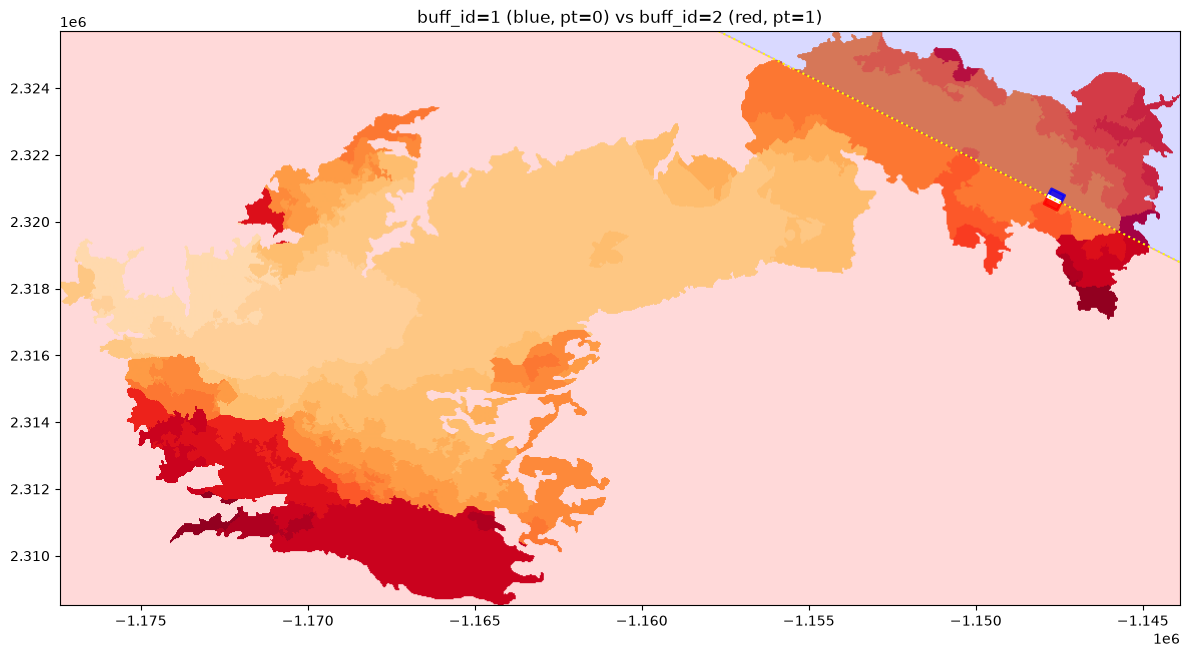

In [15]:
fig, ax = plt.subplots(figsize=(12, 10))

with rasterio.open(test_row["tif_path"]) as src:
    rasterio.plot.show(src, ax=ax, cmap="YlOrRd")
    bounds = src.bounds

ax.set_xlim(bounds.left, bounds.right)
ax.set_ylim(bounds.bottom, bounds.top)

gpd.GeoSeries([side1_geom]).plot(ax=ax, facecolor="blue", alpha=0.15, edgecolor="blue", linewidth=1)
gpd.GeoSeries([side2_geom]).plot(ax=ax, facecolor="red", alpha=0.15, edgecolor="red", linewidth=1)
gpd.GeoSeries([geom_1]).plot(ax=ax, facecolor="blue", alpha=0.8, edgecolor="blue", linewidth=2)
gpd.GeoSeries([geom_2]).plot(ax=ax, facecolor="red", alpha=0.8, edgecolor="red", linewidth=2)
gpd.GeoSeries([drop_line]).plot(ax=ax, color="white", linewidth=3, linestyle="--")
gpd.GeoSeries([extended]).plot(ax=ax, color="yellow", linewidth=1.5, linestyle=":")

ax.set_title(f"buff_id=1 (blue, pt={pair[pair['buff_id']==1]['new_pt'].iloc[0]}) vs buff_id=2 (red, pt={pair[pair['buff_id']==2]['new_pt'].iloc[0]})")
plt.tight_layout()
plt.show()

---
# Part 4: Additional Feature Engineering -- Pushing Past 90%

After presenting the raster-split results (90.1%) to the professor, error analysis revealed two failure modes:

1. **Local buffer vs. raster split disagreement** -- the two feature groups sometimes point in opposite directions (~25% of wrong predictions)
2. **Complex/irregular fire shapes** -- the full-raster split can capture unrelated fire arms that have nothing to do with a specific drop

The professor proposed two physically-motivated fixes to try:
- **Angle relation** between the earliest-DOB (fire origin) location and the drop location
- **Distance to nearest unburned area** from each polygon's centroid

Additional ideas explored alongside these: an expanded (radius-bounded) version of the raster split, pre-drop-only burned pixels, and re-testing fuel/MTBS/DEM at the larger expanded-polygon scale rather than the tiny local buffer.




## 4a -- Distance to Nearest Unburned Area

For each polygon centroid, compute distance to the nearest unburned pixel. Hypothesis: the protected side sits closer to unburned area; the origin side is more deeply surrounded by fire.

In [16]:
import numpy as np
from scipy.ndimage import distance_transform_edt
from shapely.geometry import Point
import rasterio

def compute_dist_to_unburned(tif_path, centroid_1, centroid_2, nodata_val=65535):
    """
    For each polygon centroid, compute distance to nearest unburned pixel.
    Protected side should be CLOSER to unburned area.
    Origin side should be FURTHER from unburned area (surrounded by fire).
    """
    try:
        with rasterio.open(tif_path) as src:
            arr = src.read(1)
            pixel_size = src.res[0]  # meters per pixel

            # binary mask: True = burned, False = unburned
            burned_mask = (arr != nodata_val).astype(np.uint8)

            # distance transform on burned mask
            # gives each burned pixel its distance to nearest unburned pixel
            dist_to_unburned = distance_transform_edt(burned_mask) * pixel_size

            # sample distance at each polygon centroid
            row_1, col_1 = src.index(centroid_1.x, centroid_1.y)
            row_2, col_2 = src.index(centroid_2.x, centroid_2.y)

            # clamp to raster bounds just in case
            row_1 = np.clip(row_1, 0, arr.shape[0]-1)
            col_1 = np.clip(col_1, 0, arr.shape[1]-1)
            row_2 = np.clip(row_2, 0, arr.shape[0]-1)
            col_2 = np.clip(col_2, 0, arr.shape[1]-1)

            dist_1 = float(dist_to_unburned[row_1, col_1])
            dist_2 = float(dist_to_unburned[row_2, col_2])

            return dist_1, dist_2

    except Exception as e:
        return None, None

In [ ]:
# use our known test pair from earlier
test_drop_id = df_dob["drop_id"].iloc[0]
pair = drops[drops["drop_id"] == test_drop_id]

geom_1 = pair[pair["buff_id"] == 1].iloc[0].geometry
geom_2 = pair[pair["buff_id"] == 2].iloc[0].geometry
tif_path = pair.iloc[0]["tif_path"]

centroid_1 = geom_1.centroid
centroid_2 = geom_2.centroid

dist_1, dist_2 = compute_dist_to_unburned(tif_path, centroid_1, centroid_2)

pt_1 = pair[pair["buff_id"] == 1]["new_pt"].iloc[0]
pt_2 = pair[pair["buff_id"] == 2]["new_pt"].iloc[0]

print(f"buff_id=1 (pt={pt_1}): distance to unburned = {dist_1:.1f}m")
print(f"buff_id=2 (pt={pt_2}): distance to unburned = {dist_2:.1f}m")
print(f"Hypothesis check: protected side closer to unburned? "
      f"{'✅' if (pt_1==1 and dist_1 < dist_2) or (pt_2==1 and dist_2 < dist_1) else '❌'}")

buff_id=1 (pt=1): distance to unburned = 150.0m
buff_id=2 (pt=0): distance to unburned = 84.9m
Hypothesis check: protected side closer to unburned? ❌


In [19]:
# build a quick sample across 100 drops to check overall signal
results = []
drop_pairs = drops.groupby("drop_id")

count = 0
for drop_id, pair in drop_pairs:
    if len(pair) != 2:
        continue
    if set(pair["buff_id"].astype(int)) != {1, 2}:
        continue

    geom_1 = pair[pair["buff_id"] == 1].iloc[0].geometry
    geom_2 = pair[pair["buff_id"] == 2].iloc[0].geometry
    tif_path = pair.iloc[0]["tif_path"]
    pt_1 = pair[pair["buff_id"] == 1]["new_pt"].iloc[0]

    dist_1, dist_2 = compute_dist_to_unburned(tif_path, geom_1.centroid, geom_2.centroid)

    if dist_1 is None:
        continue

    results.append({
        "drop_id": drop_id,
        "dist_1": dist_1,
        "dist_2": dist_2,
        "pt_1": pt_1,
        "hypothesis_holds": (dist_1 < dist_2) == (pt_1 == 1)
    })

    count += 1
    if count >= 100:
        break

df_check = pd.DataFrame(results)
print(f"Hypothesis holds: {df_check['hypothesis_holds'].mean():.1%} of 100 drops")

Hypothesis holds: 75.0% of 100 drops


In [20]:
from tqdm import tqdm

dist_rows = []
skipped = 0

drop_pairs = drops.groupby("drop_id")
drop_pairs_list = list(drops.groupby("drop_id"))


for drop_id, pair in tqdm(drop_pairs_list, desc="Distance extraction"):
    if len(pair) != 2:
        skipped += 1
        continue
    if set(pair["buff_id"].astype(int)) != {1, 2}:
        skipped += 1
        continue

    tif_path = pair.iloc[0]["tif_path"]
    
    row_1 = pair[pair["buff_id"] == 1].iloc[0]
    row_2 = pair[pair["buff_id"] == 2].iloc[0]
    
    centroid_1 = row_1.geometry.centroid
    centroid_2 = row_2.geometry.centroid

    dist_1, dist_2 = compute_dist_to_unburned(
        tif_path, centroid_1, centroid_2
    )

    if dist_1 is None:
        skipped += 1
        continue

    dist_rows.append({
        "event_id": row_1["Evnt_ID"],
        "buff_id": 1,
        "drop_id": drop_id,
        "dist_to_unburned": dist_1
    })
    dist_rows.append({
        "event_id": row_2["Evnt_ID"],
        "buff_id": 2,
        "drop_id": drop_id,
        "dist_to_unburned": dist_2
    })

print(f"Processed: {len(dist_rows)} rows, Skipped: {skipped}")
df_dist = pd.DataFrame(dist_rows)
df_dist.to_csv("training_features_dist.csv", index=False)

Distance extraction: 100%|██████████| 10522/10522 [07:05<00:00, 24.74it/s]


Processed: 20730 rows, Skipped: 157


In [21]:
print(df_dist.shape)
print(df_dist["dist_to_unburned"].describe())
print(df_dist["dist_to_unburned"].isna().sum())


(20730, 4)
count    20730.000000
mean       430.181019
std        900.639219
min          0.000000
25%          0.000000
50%         84.852814
75%        400.249922
max       9003.249413
Name: dist_to_unburned, dtype: float64
0


In [22]:
# merge with existing features to get pt labels
df_check = df_dist.merge(df_dob[["event_id","buff_id","drop_id","pt"]], 
                          on=["event_id","buff_id","drop_id"], how="left")
print(df_check.groupby("pt")["dist_to_unburned"].mean())

pt
0.0    467.674972
1.0    398.026036
Name: dist_to_unburned, dtype: float64


In [23]:
df_dist["dist_pair_diff"] = df_dist.groupby("drop_id")["dist_to_unburned"].transform(
    lambda x: x - x.mean()
)
# positive = further from unburned than sibling = likely origin
# negative = closer to unburned than sibling = likely protected

## 4b -- Pre-Drop Burned Pixels (Raster Split)

Same split geometry as Part 3, but only counting pixels that burned **before** the drop date -- capturing the fire state at the exact moment the pilot made the drop decision, rather than the fire's full eventual extent.

In [24]:
def extract_split_predrop_features(pair, tif_path, nodata_val=65535):
    row_1 = pair[pair["buff_id"] == 1].iloc[0]
    row_2 = pair[pair["buff_id"] == 2].iloc[0]
    geom_1 = row_1.geometry
    geom_2 = row_2.geometry
    drop_doy = row_1["drop_doy"]

    drop_line = geom_1.intersection(geom_2)
    if drop_line.is_empty:
        return None

    if drop_line.geom_type == "GeometryCollection":
        from shapely.ops import linemerge
        lines = [g for g in drop_line.geoms if "Line" in g.geom_type]
        if not lines:
            return None
        drop_line = linemerge(lines)

    if drop_line.geom_type not in ["LineString", "MultiLineString"]:
        return None

    extended = extend_line(drop_line)

    with rasterio.open(tif_path) as src:
        bounds = src.bounds
        raster_bbox = box(bounds.left, bounds.bottom, bounds.right, bounds.top)

        try:
            result = shapely_split(raster_bbox, extended)
            if len(result.geoms) != 2:
                return None
            half_A, half_B = result.geoms
        except Exception:
            return None

        centroid_1 = geom_1.centroid
        if half_A.contains(centroid_1):
            side1_geom, side2_geom = half_A, half_B
        else:
            side1_geom, side2_geom = half_B, half_A

        try:
            img_1, _ = mask(src, [side1_geom], crop=True, filled=True, nodata=nodata_val)
            img_2, _ = mask(src, [side2_geom], crop=True, filled=True, nodata=nodata_val)
        except Exception:
            return None

    def predrop_stats(pixels, drop_doy, nodata_val):
        valid = pixels[pixels != nodata_val]
        predrop = valid[valid < drop_doy]
        return {
            "predrop_burned_pixels": int(len(predrop)),
            "predrop_mean_dob":      float(np.mean(predrop)) if len(predrop) > 0 else np.nan,
            "predrop_total_pixels":  int(pixels.size)
        }

    stats_1 = predrop_stats(img_1[0], drop_doy, nodata_val)
    stats_2 = predrop_stats(img_2[0], drop_doy, nodata_val)

    stats_1.update({"event_id": row_1["Evnt_ID"], "buff_id": 1, "drop_id": row_1["drop_id"]})
    stats_2.update({"event_id": row_2["Evnt_ID"], "buff_id": 2, "drop_id": row_2["drop_id"]})

    return stats_1, stats_2

In [25]:
from tqdm import tqdm

predrop_rows = []
skipped = 0

drop_pairs_list = list(drops.groupby("drop_id"))

for drop_id, pair in tqdm(drop_pairs_list, desc="Pre-drop extraction"):
    if len(pair) != 2:
        skipped += 1
        continue
    if set(pair["buff_id"].astype(int)) != {1, 2}:
        skipped += 1
        continue

    tif_path = pair.iloc[0]["tif_path"]
    result = extract_split_predrop_features(pair, tif_path)

    if result is None:
        skipped += 1
        continue

    stats_1, stats_2 = result
    predrop_rows.append(stats_1)
    predrop_rows.append(stats_2)

print(f"Processed: {len(predrop_rows)} rows, Skipped: {skipped}")
df_predrop = pd.DataFrame(predrop_rows)
df_predrop.to_csv("training_features_predrop.csv", index=False)
print(df_predrop.head())

Pre-drop extraction: 100%|██████████| 10522/10522 [04:12<00:00, 41.62it/s] 


Processed: 20720 rows, Skipped: 162
   predrop_burned_pixels  predrop_mean_dob  predrop_total_pixels  \
0                      0               NaN                  3894   
1                      0               NaN                 15399   
2                      0               NaN                 17877   
3                      0               NaN                  1300   
4                   2182             165.0                 12213   

                event_id  buff_id  \
0  AZ3143311069520170614        1   
1  AZ3143311069520170614        2   
2  AZ3143311069520170614        1   
3  AZ3143311069520170614        2   
4  AZ3143311069520170614        1   

                                             drop_id  
0  AZ3143311069520170614_31.43126_-110.69859_2017...  
1  AZ3143311069520170614_31.43126_-110.69859_2017...  
2  AZ3143311069520170614_31.43186_-110.69839_2017...  
3  AZ3143311069520170614_31.43186_-110.69839_2017...  
4  AZ3143311069520170614_31.43273_-110.70498_2017...  


In [26]:
df = pd.read_csv("training_features_dob.csv")

In [27]:
# merge with pt labels
df_check = df_predrop.merge(
    df[["event_id", "buff_id", "drop_id", "pt"]],
    on=["event_id", "buff_id", "drop_id"],
    how="left"
)

print(df_check.groupby("pt")["predrop_burned_pixels"].mean())
print(f"\nRows with signal (predrop > 0): {(df_check['predrop_burned_pixels'] > 0).mean():.1%}")

pt
0.0    78598.203223
1.0    22179.918094
Name: predrop_burned_pixels, dtype: float64

Rows with signal (predrop > 0): 65.5%


In [29]:
results = []
count = 0

for drop_id, pair in drops.groupby("drop_id"):
    if len(pair) != 2:
        continue
    if set(pair["buff_id"].astype(int)) != {1, 2}:
        continue

    result = extract_split_predrop_features(pair, pair.iloc[0]["tif_path"])
    if result is None:
        continue

    stats_1, stats_2 = result  # unpack the tuple

    both_zero = stats_1["predrop_burned_pixels"] == 0 and stats_2["predrop_burned_pixels"] == 0
    results.append({"drop_id": drop_id, "both_zero": both_zero})

    count += 1
    if count >= 100:
        break

df_check = pd.DataFrame(results)
print(f"Both sides zero pre-drop pixels: {df_check['both_zero'].mean():.1%}")
print(f"At least one side has signal:    {(~df_check['both_zero']).mean():.1%}")

Both sides zero pre-drop pixels: 19.0%
At least one side has signal:    81.0%


## 4c -- Expanded Polygon (Strongest New Signal)

Instead of splitting the *entire* raster (which can pull in unrelated fire arms for irregularly-shaped fires), constrain the split to a radius around the drop center (25% of the raster diagonal). This keeps thousands of pixels of context per side while staying locally relevant to the specific drop -- directly addressing the professor's "complex fire shape" failure mode.

In [ ]:
def extract_expanded_polygon_features(pair, tif_path, 
                                       radius_fraction=0.25, 
                                       nodata_val=65535):
    """
    Instead of splitting the entire raster, expand each drop polygon
    to cover ~25% of the raster diagonal on its respective side.
    This avoids capturing irrelevant fire arms from complex fire shapes.
    """
    row_1 = pair[pair["buff_id"] == 1].iloc[0]
    row_2 = pair[pair["buff_id"] == 2].iloc[0]
    geom_1 = row_1.geometry
    geom_2 = row_2.geometry
    drop_doy = row_1["drop_doy"]

    drop_line = geom_1.intersection(geom_2)
    if drop_line.is_empty:
        return None

    if drop_line.geom_type == "GeometryCollection":
        from shapely.ops import linemerge
        lines = [g for g in drop_line.geoms if "Line" in g.geom_type]
        if not lines:
            return None
        drop_line = linemerge(lines)

    if drop_line.geom_type not in ["LineString", "MultiLineString"]:
        return None

    extended = extend_line(drop_line)

    with rasterio.open(tif_path) as src:
        bounds = src.bounds

        # compute raster diagonal: determines expansion radius
        raster_diagonal = ((bounds.right - bounds.left)**2 + 
                           (bounds.top - bounds.bottom)**2) ** 0.5
        radius = raster_diagonal * radius_fraction

        # split raster bounding box
        raster_bbox = box(bounds.left, bounds.bottom, bounds.right, bounds.top)
        try:
            result = shapely_split(raster_bbox, extended)
            if len(result.geoms) != 2:
                return None
            half_A, half_B = result.geoms
        except Exception:
            return None

        # match halves to buff_ids
        centroid_1 = geom_1.centroid
        if half_A.contains(centroid_1):
            side1_geom, side2_geom = half_A, half_B
        else:
            side1_geom, side2_geom = half_B, half_A

        # expand: intersect each half with a circle around drop center
        drop_center = drop_line.centroid
        local_buffer = drop_center.buffer(radius)

        side1_local = side1_geom.intersection(local_buffer)
        side2_local = side2_geom.intersection(local_buffer)

        if side1_local.is_empty or side2_local.is_empty:
            return None

        # sample pixels in expanded local areas
        try:
            img_1, _ = mask(src, [side1_local], crop=True, 
                           filled=True, nodata=nodata_val)
            img_2, _ = mask(src, [side2_local], crop=True, 
                           filled=True, nodata=nodata_val)
        except Exception:
            return None

    pixels_1 = img_1[0]
    pixels_2 = img_2[0]

    def compute_stats(pixels, drop_doy, nodata_val):
        valid = pixels[pixels != nodata_val]
        if len(valid) == 0:
            return {
                "exp_mean_dob": np.nan,
                "exp_burned_pixels": 0,
                "exp_unburned_pixels": int(np.sum(pixels == nodata_val)),
                "exp_early_pixels": 0,
                "exp_late_pixels": 0,
                "exp_total_pixels": int(pixels.size)
            }
        return {
            "exp_mean_dob":       float(np.mean(valid)),
            "exp_burned_pixels":  int(len(valid)),
            "exp_unburned_pixels": int(np.sum(pixels == nodata_val)),
            "exp_early_pixels":   int(np.sum(valid < drop_doy)),
            "exp_late_pixels":    int(np.sum(valid > drop_doy)),
            "exp_total_pixels":   int(pixels.size)
        }

    stats_1 = compute_stats(pixels_1, drop_doy, nodata_val)
    stats_2 = compute_stats(pixels_2, drop_doy, nodata_val)

    stats_1.update({"event_id": row_1["Evnt_ID"], 
                    "buff_id": 1, 
                    "drop_id": row_1["drop_id"]})
    stats_2.update({"event_id": row_2["Evnt_ID"], 
                    "buff_id": 2, 
                    "drop_id": row_2["drop_id"]})

    return stats_1, stats_2

In [36]:
test_drop_id = drops["drop_id"].iloc[0]
pair = drops[drops["drop_id"] == test_drop_id]

result = extract_expanded_polygon_features(pair, pair.iloc[0]["tif_path"])

if result:
    stats_1, stats_2 = result
    pt_1 = pair[pair["buff_id"] == 1]["new_pt"].iloc[0]
    pt_2 = pair[pair["buff_id"] == 2]["new_pt"].iloc[0]

    print(f"buff_id=1 (pt={pt_1}): burned={stats_1['exp_burned_pixels']}, "
          f"unburned={stats_1['exp_unburned_pixels']}, "
          f"early={stats_1['exp_early_pixels']}")
    print(f"buff_id=2 (pt={pt_2}): burned={stats_2['exp_burned_pixels']}, "
          f"unburned={stats_2['exp_unburned_pixels']}, "
          f"early={stats_2['exp_early_pixels']}")
    print(f"Total pixels per side: {stats_1['exp_total_pixels']} vs {stats_2['exp_total_pixels']}")
else:
    print("Failed")

buff_id=1 (pt=1): burned=878, unburned=684, early=0
buff_id=2 (pt=0): burned=2013, unburned=1821, early=0
Total pixels per side: 1562 vs 3834


In [31]:
results = []
count = 0

for drop_id, pair in drops.groupby("drop_id"):
    if len(pair) != 2:
        continue
    if set(pair["buff_id"].astype(int)) != {1, 2}:
        continue

    result = extract_expanded_polygon_features(pair, pair.iloc[0]["tif_path"])
    if result is None:
        continue

    stats_1, stats_2 = result
    pt_1 = pair[pair["buff_id"] == 1]["new_pt"].iloc[0]

    hypothesis_holds = (pt_1 == 1) == (stats_1["exp_burned_pixels"] < stats_2["exp_burned_pixels"])
    results.append({"holds": hypothesis_holds})

    count += 1
    if count >= 500:
        break

df_check = pd.DataFrame(results)
print(f"Hypothesis holds: {df_check['holds'].mean():.1%} of 500 drops")

Hypothesis holds: 83.8% of 500 drops


In [32]:
from tqdm import tqdm

exp_rows = []
skipped = 0

drop_pairs_list = list(drops.groupby("drop_id"))

for drop_id, pair in tqdm(drop_pairs_list, desc="Expanded polygon extraction"):
    if len(pair) != 2:
        skipped += 1
        continue
    if set(pair["buff_id"].astype(int)) != {1, 2}:
        skipped += 1
        continue

    tif_path = pair.iloc[0]["tif_path"]
    result = extract_expanded_polygon_features(pair, tif_path)

    if result is None:
        skipped += 1
        continue

    stats_1, stats_2 = result
    exp_rows.append(stats_1)
    exp_rows.append(stats_2)

print(f"Processed: {len(exp_rows)} rows, Skipped: {skipped}")
df_exp = pd.DataFrame(exp_rows)
df_exp.to_csv("training_features_expanded.csv", index=False)

Expanded polygon extraction: 100%|██████████| 10522/10522 [02:26<00:00, 72.05it/s] 


Processed: 20716 rows, Skipped: 164


In [33]:
# quick class separation check
df_check = df_exp.merge(
    pd.read_csv("training_features_dob.csv")[["event_id","buff_id","drop_id","pt"]],
    on=["event_id","buff_id","drop_id"],
    how="left"
)
print(df_check.groupby("pt")[["exp_burned_pixels","exp_unburned_pixels","exp_early_pixels"]].mean())

     exp_burned_pixels  exp_unburned_pixels  exp_early_pixels
pt                                                           
0.0       56945.317024         72673.395773      29221.952422
1.0       23671.485077         71389.030825       8180.719151


## 4d -- Expanded Polygon + Time-Weighted Burn Score



In [34]:
def extract_expanded_weighted_features(pair, tif_path,
                                        radius_fraction=0.25,
                                        nodata_val=65535):
    """
    Same as expanded polygon but adds time-weighted burned score.
    Pixels that burned earlier (relative to drop date) get higher weight.
    This captures fire momentum/history more accurately than raw counts.
    """
    row_1 = pair[pair["buff_id"] == 1].iloc[0]
    row_2 = pair[pair["buff_id"] == 2].iloc[0]
    geom_1 = row_1.geometry
    geom_2 = row_2.geometry
    drop_doy = row_1["drop_doy"]

    drop_line = geom_1.intersection(geom_2)
    if drop_line.is_empty:
        return None

    if drop_line.geom_type == "GeometryCollection":
        from shapely.ops import linemerge
        lines = [g for g in drop_line.geoms if "Line" in g.geom_type]
        if not lines:
            return None
        drop_line = linemerge(lines)

    if drop_line.geom_type not in ["LineString", "MultiLineString"]:
        return None

    extended = extend_line(drop_line)

    with rasterio.open(tif_path) as src:
        bounds = src.bounds
        raster_diagonal = ((bounds.right - bounds.left)**2 +
                           (bounds.top - bounds.bottom)**2) ** 0.5
        radius = raster_diagonal * radius_fraction
        raster_bbox = box(bounds.left, bounds.bottom,
                         bounds.right, bounds.top)

        try:
            result = shapely_split(raster_bbox, extended)
            if len(result.geoms) != 2:
                return None
            half_A, half_B = result.geoms
        except Exception:
            return None

        centroid_1 = geom_1.centroid
        if half_A.contains(centroid_1):
            side1_geom, side2_geom = half_A, half_B
        else:
            side1_geom, side2_geom = half_B, half_A

        drop_center = drop_line.centroid
        local_buffer = drop_center.buffer(radius)
        side1_local = side1_geom.intersection(local_buffer)
        side2_local = side2_geom.intersection(local_buffer)

        if side1_local.is_empty or side2_local.is_empty:
            return None

        try:
            img_1, _ = mask(src, [side1_local], crop=True,
                           filled=True, nodata=nodata_val)
            img_2, _ = mask(src, [side2_local], crop=True,
                           filled=True, nodata=nodata_val)
        except Exception:
            return None

    def weighted_stats(pixels, drop_doy, nodata_val):
        valid = pixels[pixels != nodata_val]

        if len(valid) == 0:
            return {
                "exp_weighted_burn_score": 0,
                "exp_weighted_mean_dob": np.nan,
                "exp_burned_pixels": 0,
                "exp_unburned_pixels": int(np.sum(pixels == nodata_val)),
                "exp_early_pixels": 0,
                "exp_late_pixels": 0,
                "exp_total_pixels": int(pixels.size)
            }

        # weight = days before drop (earlier = higher weight)
        # pixels burned after drop get weight 0
        weights = np.maximum(0, drop_doy - valid)
        weighted_score = float(np.sum(weights))

        # weighted mean DOB (weighted toward earlier pixels)
        if weighted_score > 0:
            weighted_mean = float(np.average(valid, weights=weights))
        else:
            weighted_mean = float(np.mean(valid))

        return {
            # TIME-WEIGHTED: earlier burns count more
            "exp_weighted_burn_score": weighted_score,
            "exp_weighted_mean_dob":   weighted_mean,
            # raw counts (same as before for comparison)
            "exp_burned_pixels":       int(len(valid)),
            "exp_unburned_pixels":     int(np.sum(pixels == nodata_val)),
            "exp_early_pixels":        int(np.sum(valid < drop_doy)),
            "exp_late_pixels":         int(np.sum(valid > drop_doy)),
            "exp_total_pixels":        int(pixels.size)
        }

    stats_1 = weighted_stats(img_1[0], drop_doy, nodata_val)
    stats_2 = weighted_stats(img_2[0], drop_doy, nodata_val)

    stats_1.update({"event_id": row_1["Evnt_ID"],
                    "buff_id": 1,
                    "drop_id": row_1["drop_id"]})
    stats_2.update({"event_id": row_2["Evnt_ID"],
                    "buff_id": 2,
                    "drop_id": row_2["drop_id"]})

    return stats_1, stats_2

In [ ]:
test_drop_id = drops["drop_id"].iloc[0]
pair = drops[drops["drop_id"] == test_drop_id]

result = extract_expanded_weighted_features(pair, pair.iloc[0]["tif_path"])

if result:
    stats_1, stats_2 = result
    pt_1 = pair[pair["buff_id"] == 1]["new_pt"].iloc[0]
    pt_2 = pair[pair["buff_id"] == 2]["new_pt"].iloc[0]

    print(f"buff_id=1 (pt={pt_1}):")
    print(f"  weighted_score: {stats_1['exp_weighted_burn_score']:.1f}")
    print(f"  early_pixels:   {stats_1['exp_early_pixels']}")
    print(f"  burned_pixels:  {stats_1['exp_burned_pixels']}")

    print(f"buff_id=2 (pt={pt_2}):")
    print(f"  weighted_score: {stats_2['exp_weighted_burn_score']:.1f}")
    print(f"  early_pixels:   {stats_2['exp_early_pixels']}")
    print(f"  burned_pixels:  {stats_2['exp_burned_pixels']}")

    print(f"\nHypothesis (origin has higher weighted score):")
    holds = (pt_1 == 0) == (stats_1['exp_weighted_burn_score'] > stats_2['exp_weighted_burn_score'])
    print(f"{'Yes' if holds else 'No'}")

buff_id=1 (pt=1):
  weighted_score: 0.0
  early_pixels:   0
  burned_pixels:  878
buff_id=2 (pt=0):
  weighted_score: 0.0
  early_pixels:   0
  burned_pixels:  2013

Hypothesis (origin has higher weighted score):
✅


## 4e -- Fire-Start Angle / Direction 



In [36]:
def compute_fire_start_angle(tif_path, centroid_1, centroid_2, nodata_val=65535):
    """
    Find fire start location (min DOB pixel) and compute
    angle from fire start to each polygon centroid.
    """
    try:
        with rasterio.open(tif_path) as src:
            arr = src.read(1).astype(float)
            arr[arr == nodata_val] = np.inf

            # find pixel with minimum DOB = fire start location
            min_idx = np.unravel_index(arr.argmin(), arr.shape)
            fire_start_x, fire_start_y = src.xy(min_idx[0], min_idx[1])

        import math

        # angle from fire start to each centroid
        angle_1 = math.atan2(
            centroid_1.y - fire_start_y,
            centroid_1.x - fire_start_x
        )
        angle_2 = math.atan2(
            centroid_2.y - fire_start_y,
            centroid_2.x - fire_start_x
        )

        # distance from fire start to each centroid
        dist_from_start_1 = math.sqrt(
            (centroid_1.x - fire_start_x)**2 +
            (centroid_1.y - fire_start_y)**2
        )
        dist_from_start_2 = math.sqrt(
            (centroid_2.x - fire_start_x)**2 +
            (centroid_2.y - fire_start_y)**2
        )

        # angle difference between the two sides
        angle_diff = abs(angle_1 - angle_2)

        return {
            "angle_to_side1": angle_1,
            "angle_to_side2": angle_2,
            "dist_from_fire_start_1": dist_from_start_1,
            "dist_from_fire_start_2": dist_from_start_2,
            "angle_diff_between_sides": angle_diff
        }

    except Exception:
        return None

In [ ]:
test_drop_id = drops["drop_id"].iloc[0]
pair = drops[drops["drop_id"] == test_drop_id]

geom_1 = pair[pair["buff_id"] == 1].iloc[0].geometry
geom_2 = pair[pair["buff_id"] == 2].iloc[0].geometry
tif_path = pair.iloc[0]["tif_path"]
pt_1 = pair[pair["buff_id"] == 1]["new_pt"].iloc[0]
pt_2 = pair[pair["buff_id"] == 2]["new_pt"].iloc[0]

result = compute_fire_start_angle(
    tif_path, geom_1.centroid, geom_2.centroid
)

print(f"buff_id=1 (pt={pt_1}): dist from fire start = {result['dist_from_fire_start_1']:.1f}m")
print(f"buff_id=2 (pt={pt_2}): dist from fire start = {result['dist_from_fire_start_2']:.1f}m")
print(f"Hypothesis: origin side CLOSER to fire start")
print(f"Holds: {'Yes' if (pt_1==0) == (result['dist_from_fire_start_1'] < result['dist_from_fire_start_2']) else 'No'}")

buff_id=1 (pt=1): dist from fire start = 3710.1m
buff_id=2 (pt=0): dist from fire start = 3537.9m
Hypothesis: origin side CLOSER to fire start
Holds: ✅


In [37]:
results = []
count = 0

for drop_id, pair in drops.groupby("drop_id"):
    if len(pair) != 2:
        continue
    if set(pair["buff_id"].astype(int)) != {1, 2}:
        continue

    geom_1 = pair[pair["buff_id"] == 1].iloc[0].geometry
    geom_2 = pair[pair["buff_id"] == 2].iloc[0].geometry
    tif_path = pair.iloc[0]["tif_path"]
    pt_1 = pair[pair["buff_id"] == 1]["new_pt"].iloc[0]

    result = compute_fire_start_angle(
        tif_path, geom_1.centroid, geom_2.centroid
    )
    if result is None:
        continue

    origin_closer = result["dist_from_fire_start_1"] < result["dist_from_fire_start_2"]
    hypothesis_holds = (pt_1 == 0) == origin_closer

    results.append({"drop_id": drop_id, "holds": hypothesis_holds})
    count += 1
    if count >= 100:
        break

df_check = pd.DataFrame(results)
print(f"Hypothesis holds: {df_check['holds'].mean():.1%} of 100 drops")

Hypothesis holds: 61.0% of 100 drops


In [38]:
import math

def compute_fire_angle_features(tif_path, centroid_1, centroid_2, nodata_val=65535):
    try:
        with rasterio.open(tif_path) as src:
            arr = src.read(1).astype(float)
            arr[arr == nodata_val] = np.inf
            min_idx = np.unravel_index(arr.argmin(), arr.shape)
            fire_start_x, fire_start_y = src.xy(min_idx[0], min_idx[1])

        # midpoint between the two polygon centroids = drop center
        drop_center_x = (centroid_1.x + centroid_2.x) / 2
        drop_center_y = (centroid_1.y + centroid_2.y) / 2

        # vector from drop center to fire start
        vec_to_fire_x = fire_start_x - drop_center_x
        vec_to_fire_y = fire_start_y - drop_center_y

        # vector from drop center to each centroid
        vec_to_c1_x = centroid_1.x - drop_center_x
        vec_to_c1_y = centroid_1.y - drop_center_y

        vec_to_c2_x = centroid_2.x - drop_center_x
        vec_to_c2_y = centroid_2.y - drop_center_y

        # magnitude of fire direction vector
        fire_mag = math.sqrt(vec_to_fire_x**2 + vec_to_fire_y**2)
        mag_c1 = math.sqrt(vec_to_c1_x**2 + vec_to_c1_y**2)
        mag_c2 = math.sqrt(vec_to_c2_x**2 + vec_to_c2_y**2)

        if fire_mag == 0 or mag_c1 == 0 or mag_c2 == 0:
            return None

        # dot product = cos(angle) between fire direction and centroid direction
        # positive = same direction as fire = origin side
        # negative = opposite direction = protected side
        dot_1 = (vec_to_fire_x * vec_to_c1_x + vec_to_fire_y * vec_to_c1_y) / (fire_mag * mag_c1)
        dot_2 = (vec_to_fire_x * vec_to_c2_x + vec_to_fire_y * vec_to_c2_y) / (fire_mag * mag_c2)

        # cross product = sin(angle) = which side of the fire direction line
        cross_1 = (vec_to_fire_x * vec_to_c1_y - vec_to_fire_y * vec_to_c1_x) / (fire_mag * mag_c1)
        cross_2 = (vec_to_fire_x * vec_to_c2_x - vec_to_fire_y * vec_to_c2_x) / (fire_mag * mag_c2)

        return {
            "dot_to_fire_1": dot_1,   # +1 = perfectly aligned with fire direction
            "dot_to_fire_2": dot_2,   # -1 = opposite to fire direction
            "cross_to_fire_1": cross_1,
            "cross_to_fire_2": cross_2,
            "dot_diff": dot_1 - dot_2  # positive = side 1 more toward fire = origin
        }

    except Exception:
        return None

In [ ]:
result = compute_fire_angle_features(
    tif_path, geom_1.centroid, geom_2.centroid
)

print(f"buff_id=1 (pt={pt_1}): dot = {result['dot_to_fire_1']:.3f}")
print(f"buff_id=2 (pt={pt_2}): dot = {result['dot_to_fire_2']:.3f}")
print(f"dot_diff: {result['dot_diff']:.3f}")
print(f"Hypothesis: origin side has higher dot product")
print(f"Holds: {'Yes' if (pt_1==0) == (result['dot_to_fire_1'] > result['dot_to_fire_2']) else 'No'}")

buff_id=1 (pt=1): dot = -0.850
buff_id=2 (pt=0): dot = 0.850
dot_diff: -1.699
Hypothesis: origin side has higher dot product
Holds: ✅


In [40]:
results_angle = []
count = 0

for drop_id, pair in drops.groupby("drop_id"):
    if len(pair) != 2:
        continue
    if set(pair["buff_id"].astype(int)) != {1, 2}:
        continue

    geom_1 = pair[pair["buff_id"] == 1].iloc[0].geometry
    geom_2 = pair[pair["buff_id"] == 2].iloc[0].geometry
    tif_path = pair.iloc[0]["tif_path"]
    pt_1 = pair[pair["buff_id"] == 1]["new_pt"].iloc[0]

    result = compute_fire_angle_features(
        tif_path, geom_1.centroid, geom_2.centroid
    )
    if result is None:
        continue

    # origin side should have HIGHER dot product (more aligned with fire direction)
    origin_more_aligned = result["dot_to_fire_1"] > result["dot_to_fire_2"]
    hypothesis_holds = (pt_1 == 0) == origin_more_aligned

    results_angle.append({
        "drop_id": drop_id,
        "dot_1": result["dot_to_fire_1"],
        "dot_2": result["dot_to_fire_2"],
        "dot_diff": result["dot_diff"],
        "pt_1": pt_1,
        "holds": hypothesis_holds
    })

    count += 1
    if count >= 100:
        break

df_angle_check = pd.DataFrame(results_angle)
print(f"Angle hypothesis holds: {df_angle_check['holds'].mean():.1%} of 100 drops")
print(f"\nMean dot product by pt:")
print(f"pt=0 (origin):    {df_angle_check[df_angle_check['pt_1']==0]['dot_1'].mean():.3f}")
print(f"pt=1 (protected): {df_angle_check[df_angle_check['pt_1']==1]['dot_1'].mean():.3f}")

Angle hypothesis holds: 61.0% of 100 drops

Mean dot product by pt:
pt=0 (origin):    0.165
pt=1 (protected): -0.217


## 4f -- LANDFIRE Fuel on Expanded Polygon



In [41]:
from scipy import stats as scipy_stats

results = []
count = 0

for drop_id, pair in drops.groupby("drop_id"):
    if len(pair) != 2:
        continue
    if set(pair["buff_id"].astype(int)) != {1, 2}:
        continue

    geom_1 = pair[pair["buff_id"] == 1].iloc[0].geometry
    geom_2 = pair[pair["buff_id"] == 2].iloc[0].geometry
    pt_1 = pair[pair["buff_id"] == 1]["new_pt"].iloc[0]

    # get expanded geometries
    drop_line = geom_1.intersection(geom_2)
    if drop_line.is_empty:
        continue

    try:
        extended = extend_line(drop_line)
        with rasterio.open(pair.iloc[0]["tif_path"]) as src:
            bounds = src.bounds
            raster_diagonal = ((bounds.right - bounds.left)**2 +
                               (bounds.top - bounds.bottom)**2) ** 0.5
            radius = raster_diagonal * 0.25
            raster_bbox = box(bounds.left, bounds.bottom,
                             bounds.right, bounds.top)
            result = shapely_split(raster_bbox, extended)
            if len(result.geoms) != 2:
                continue
            half_A, half_B = result.geoms
            centroid_1 = geom_1.centroid
            if half_A.contains(centroid_1):
                side1_geom, side2_geom = half_A, half_B
            else:
                side1_geom, side2_geom = half_B, half_A
            drop_center = drop_line.centroid
            local_buffer = drop_center.buffer(radius)
            side1_local = side1_geom.intersection(local_buffer)
            side2_local = side2_geom.intersection(local_buffer)
    except Exception:
        continue

    # sample fuel under expanded polygons
    fuel_path = "training_data/LANDFIRE_fuel/tiff/LC22_F13_220.tif"

    try:
        with rasterio.open(fuel_path) as src:
            img_1, _ = mask(src, [side1_local], crop=True,
                           filled=True, nodata=32767)
            img_2, _ = mask(src, [side2_local], crop=True,
                           filled=True, nodata=32767)

        valid_1 = img_1[0][(img_1[0] != 32767) & (img_1[0] != -9999)]
        valid_2 = img_2[0][(img_2[0] != 32767) & (img_2[0] != -9999)]

        if len(valid_1) == 0 or len(valid_2) == 0:
            continue

        dom_1 = int(scipy_stats.mode(valid_1, keepdims=True).mode[0])
        dom_2 = int(scipy_stats.mode(valid_2, keepdims=True).mode[0])

        results.append({
            "drop_id": drop_id,
            "dominant_fuel_1": dom_1,
            "dominant_fuel_2": dom_2,
            "pt_1": pt_1,
            "fuels_differ": dom_1 != dom_2
        })
    except Exception:
        continue

    count += 1
    if count >= 100:
        break

df_fuel_check = pd.DataFrame(results)
print(f"Drops where fuel type differs between sides: {df_fuel_check['fuels_differ'].mean():.1%}")
print(f"\nDominant fuel distribution side 1:\n{df_fuel_check['dominant_fuel_1'].value_counts()}")

Drops where fuel type differs between sides: 67.0%

Dominant fuel distribution side 1:
dominant_fuel_1
2    49
5    22
1    19
8    10
Name: count, dtype: int64


In [42]:
from tqdm import tqdm
from scipy import stats as scipy_stats

fuel_path = "training_data/LANDFIRE_fuel/tiff/LC22_F13_220.tif"

fuel_exp_rows = []
skipped = 0

drop_pairs_list = list(drops.groupby("drop_id"))

for drop_id, pair in tqdm(drop_pairs_list, desc="Fuel expanded extraction"):
    if len(pair) != 2:
        skipped += 1
        continue
    if set(pair["buff_id"].astype(int)) != {1, 2}:
        skipped += 1
        continue

    row_1 = pair[pair["buff_id"] == 1].iloc[0]
    row_2 = pair[pair["buff_id"] == 2].iloc[0]
    geom_1 = row_1.geometry
    geom_2 = row_2.geometry

    drop_line = geom_1.intersection(geom_2)
    if drop_line.is_empty:
        skipped += 1
        continue

    if drop_line.geom_type == "GeometryCollection":
        from shapely.ops import linemerge
        lines = [g for g in drop_line.geoms if "Line" in g.geom_type]
        if not lines:
            skipped += 1
            continue
        drop_line = linemerge(lines)

    if drop_line.geom_type not in ["LineString", "MultiLineString"]:
        skipped += 1
        continue

    try:
        extended = extend_line(drop_line)

        with rasterio.open(row_1["tif_path"]) as src:
            bounds = src.bounds
            raster_diagonal = ((bounds.right - bounds.left)**2 +
                               (bounds.top - bounds.bottom)**2) ** 0.5
            radius = raster_diagonal * 0.25
            raster_bbox = box(bounds.left, bounds.bottom,
                             bounds.right, bounds.top)
            result = shapely_split(raster_bbox, extended)
            if len(result.geoms) != 2:
                skipped += 1
                continue
            half_A, half_B = result.geoms

        centroid_1 = geom_1.centroid
        if half_A.contains(centroid_1):
            side1_geom, side2_geom = half_A, half_B
        else:
            side1_geom, side2_geom = half_B, half_A

        drop_center = drop_line.centroid
        local_buffer = drop_center.buffer(radius)
        side1_local = side1_geom.intersection(local_buffer)
        side2_local = side2_geom.intersection(local_buffer)

        if side1_local.is_empty or side2_local.is_empty:
            skipped += 1
            continue

        with rasterio.open(fuel_path) as src:
            img_1, _ = mask(src, [side1_local], crop=True,
                           filled=True, nodata=32767)
            img_2, _ = mask(src, [side2_local], crop=True,
                           filled=True, nodata=32767)

        def fuel_stats(pixels, nodata_val=32767):
            valid = pixels[(pixels != nodata_val) & (pixels != -9999)]
            if len(valid) == 0:
                return {
                    "exp_dominant_fuel": np.nan,
                    "exp_fuel_diversity": 0,
                    "exp_grass_pixels": 0,
                    "exp_shrub_pixels": 0,
                    "exp_timber_pixels": 0,
                    "exp_nonburnable_pixels": 0,
                    "exp_fuel_total_pixels": 0
                }
            return {
                "exp_dominant_fuel":      int(scipy_stats.mode(valid, keepdims=True).mode[0]),
                "exp_fuel_diversity":     int(len(np.unique(valid))),
                "exp_grass_pixels":       int(np.sum(np.isin(valid, [1,2,3]))),
                "exp_shrub_pixels":       int(np.sum(np.isin(valid, [4,5,6,7]))),
                "exp_timber_pixels":      int(np.sum(np.isin(valid, [8,9,10]))),
                "exp_nonburnable_pixels": int(np.sum(np.isin(valid, [91,92,93,98,99]))),
                "exp_fuel_total_pixels":  int(len(valid))
            }

        stats_1 = fuel_stats(img_1[0])
        stats_2 = fuel_stats(img_2[0])

        stats_1.update({"event_id": row_1["Evnt_ID"],
                        "buff_id": 1,
                        "drop_id": drop_id})
        stats_2.update({"event_id": row_2["Evnt_ID"],
                        "buff_id": 2,
                        "drop_id": drop_id})

        fuel_exp_rows.append(stats_1)
        fuel_exp_rows.append(stats_2)

    except Exception:
        skipped += 1
        continue

print(f"Processed: {len(fuel_exp_rows)} rows, Skipped: {skipped}")
df_fuel_exp = pd.DataFrame(fuel_exp_rows)
df_fuel_exp.to_csv("training_features_fuel_expanded.csv", index=False)
print(df_fuel_exp.head())

Fuel expanded extraction: 100%|██████████| 10522/10522 [04:24<00:00, 39.82it/s]


Processed: 20716 rows, Skipped: 164
   exp_dominant_fuel  exp_fuel_diversity  exp_grass_pixels  exp_shrub_pixels  \
0                  5                   5               587               731   
1                  5                   5              1187              1707   
2                  5                   5              1461              2027   
3                  2                   5               434               150   
4                  2                   5               768               509   

   exp_timber_pixels  exp_nonburnable_pixels  exp_fuel_total_pixels  \
0                 75                       0                   1393   
1                174                       0                   3068   
2                214                       0                   3702   
3                 34                       0                    618   
4                118                       0                   1395   

                event_id  buff_id  \
0  AZ31433110695201

In [43]:
# merge with pt labels
df_check = df_fuel_exp.merge(
    pd.read_csv("training_features_dob.csv")[["event_id","buff_id","drop_id","pt"]],
    on=["event_id","buff_id","drop_id"],
    how="left"
)

print(df_check.groupby("pt")[["exp_grass_pixels","exp_shrub_pixels",
                               "exp_timber_pixels"]].mean())

     exp_grass_pixels  exp_shrub_pixels  exp_timber_pixels
pt                                                        
0.0      19577.409477      36561.948273       24505.096024
1.0      12896.897740      26016.700264       17263.758587


## 4g -- MTBS Burn Severity on Expanded Polygon



In [44]:
mtbs_rasters = {
    2017: "training_data/mtbs_mosaic/2017/mtbs_CONUS_2017.tif",
    2018: "training_data/mtbs_mosaic/2018/mtbs_CONUS_2018.tif",
    2019: "training_data/mtbs_mosaic/2019/mtbs_CONUS_2019.tif"
}

results_mtbs = []
count = 0

for drop_id, pair in drops.groupby("drop_id"):
    if len(pair) != 2:
        continue
    if set(pair["buff_id"].astype(int)) != {1, 2}:
        continue

    row_1 = pair[pair["buff_id"] == 1].iloc[0]
    year = int(row_1["loclYr1"])
    if year not in mtbs_rasters:
        continue

    geom_1 = row_1.geometry
    geom_2 = pair[pair["buff_id"] == 2].iloc[0].geometry
    pt_1 = row_1["new_pt"]

    drop_line = geom_1.intersection(geom_2)
    if drop_line.is_empty:
        continue

    try:
        extended = extend_line(drop_line)
        with rasterio.open(row_1["tif_path"]) as src:
            bounds = src.bounds
            raster_diagonal = ((bounds.right-bounds.left)**2 +
                               (bounds.top-bounds.bottom)**2)**0.5
            radius = raster_diagonal * 0.25
            raster_bbox = box(bounds.left, bounds.bottom,
                             bounds.right, bounds.top)
            result = shapely_split(raster_bbox, extended)
            if len(result.geoms) != 2:
                continue
            half_A, half_B = result.geoms

        centroid_1 = geom_1.centroid
        if half_A.contains(centroid_1):
            side1_geom, side2_geom = half_A, half_B
        else:
            side1_geom, side2_geom = half_B, half_A

        drop_center = drop_line.centroid
        local_buffer = drop_center.buffer(radius)
        side1_local = side1_geom.intersection(local_buffer)
        side2_local = side2_geom.intersection(local_buffer)

        with rasterio.open(mtbs_rasters[year]) as src:
            img_1, _ = mask(src, [side1_local], crop=True,
                           filled=True, nodata=0)
            img_2, _ = mask(src, [side2_local], crop=True,
                           filled=True, nodata=0)

        valid_1 = img_1[0][(img_1[0] != 0) & (img_1[0] != 6)]
        valid_2 = img_2[0][(img_2[0] != 0) & (img_2[0] != 6)]

        if len(valid_1) == 0 or len(valid_2) == 0:
            continue

        mean_sev_1 = float(np.mean(valid_1))
        mean_sev_2 = float(np.mean(valid_2))

        # origin side should have HIGHER severity
        holds = (pt_1 == 0) == (mean_sev_1 > mean_sev_2)
        results_mtbs.append({
            "drop_id": drop_id,
            "mean_sev_1": mean_sev_1,
            "mean_sev_2": mean_sev_2,
            "pt_1": pt_1,
            "holds": holds
        })

    except Exception:
        continue

    count += 1
    if count >= 100:
        break

df_mtbs_check = pd.DataFrame(results_mtbs)
print(f"MTBS hypothesis holds: {df_mtbs_check['holds'].mean():.1%} of {len(df_mtbs_check)} drops")
print(f"\nMean severity by pt:")
print(df_mtbs_check.groupby("pt_1")[["mean_sev_1"]].mean())

MTBS hypothesis holds: 58.0% of 100 drops

Mean severity by pt:
      mean_sev_1
pt_1            
0       1.898984
1       1.842899


## 4h -- DEM Terrain (Elevation / Slope / Aspect)



In [45]:
drops["state"] = drops["Evnt_ID"].str[:2]
print(drops["state"].value_counts())

state
CA    7086
NV    2446
MT    1920
OR    1856
AZ    1749
ID    1701
UT    1434
CO    1066
WA     898
WY     590
NM     488
Name: count, dtype: int64


In [52]:
import py3dep
import os

os.makedirs("dem_tiles", exist_ok=True)

# bounding boxes per state (in WGS84 lat/lon)
drops_wgs84 = drops.to_crs("EPSG:4326")
drops_wgs84["state"] = drops["Evnt_ID"].str[:2]

state_bounds = drops_wgs84.groupby("state").apply(
    lambda g: g.total_bounds  # [minx, miny, maxx, maxy]
)

print("State bounding boxes:")
for state, bounds in state_bounds.items():
    print(f"{state}: {bounds.round(2)}")

State bounding boxes:
AZ: [-112.49   31.43 -109.36   35.27]
CA: [-123.67   32.64 -116.82   42.03]
CO: [-108.88   37.38 -104.66   40.86]
ID: [-117.09   41.94 -111.52   47.86]
MT: [-115.66   44.99 -105.21   49.  ]
NM: [-108.97   31.36 -103.03   37.01]
NV: [-120.01   37.19 -113.89   41.99]
OR: [-124.12   42.09 -117.22   45.96]
UT: [-113.45   37.39 -109.02   42.02]
WA: [-121.37   46.44 -117.25   48.7 ]
WY: [-110.61   41.01 -106.04   44.22]


/var/folders/gp/hgxpjqv54rg2r22rtswcl76r0000gn/T/ipykernel_83301/3652374965.py:10: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  state_bounds = drops_wgs84.groupby("state").apply(


In [14]:
buffer = 0.1  # small buffer around fire locations

for state, bounds in state_bounds.items():
    output = f"dem_tiles/dem_{state}.tif"
    
    if os.path.exists(output):
        print(f"{state}: already exists ✅")
        continue
    
    minx, miny, maxx, maxy = bounds
    bbox = (minx - buffer, miny - buffer,
            maxx + buffer, maxy + buffer)
    
    print(f"{state}: downloading {bbox}...")
    try:
        dem = py3dep.get_map(
            "DEM", bbox,
            resolution=30,
            geo_crs="EPSG:4326"
        )
        dem.rio.to_raster(output)
        print(f"{state}: saved ✅")
    except Exception as e:
        print(f"{state}: failed — {e}")

AZ: downloading (np.float64(-112.59206001544482), np.float64(31.329030632456274), np.float64(-109.26272214769067), np.float64(35.37251456252349))...
AZ: failed — 
CA: downloading (np.float64(-123.77118393717345), np.float64(32.5407746538586), np.float64(-116.719883560313), np.float64(42.12536204176098))...
CA: failed — 
CO: downloading (np.float64(-108.98230279674502), np.float64(37.28154144282531), np.float64(-104.55823030438738), np.float64(40.957045196918294))...


KeyboardInterrupt: 

In [53]:
import py3dep
import os
import rasterio

os.makedirs("dem_tiles", exist_ok=True)

drops_wgs84 = drops.to_crs("EPSG:4326")

# get unique fires
fires = drops_wgs84.groupby("Evnt_ID")

failed = []
skipped = 0

for event_id, fire_drops in fires:
    output = f"dem_tiles/dem_{event_id}.tif"
    
    if os.path.exists(output):
        skipped += 1
        continue
    
    # bounding box of this specific fire's drops
    bounds = fire_drops.total_bounds
    minx, miny, maxx, maxy = bounds
    buffer = 0.05  # ~5km buffer, smaller than state-level
    
    bbox = (minx - buffer, miny - buffer,
            maxx + buffer, maxy + buffer)
    
    try:
        dem = py3dep.get_map(
            "DEM", bbox,
            resolution=30,
            geo_crs="EPSG:4326"
        )
        dem.rio.to_raster(output)
    except Exception as e:
        failed.append({"event_id": event_id, "error": str(e)})

print(f"Skipped (already exist): {skipped}")
print(f"Failed: {len(failed)}")
if failed:
    print(failed[:5])

Skipped (already exist): 424
Failed: 0


In [54]:
import os
dem_files = [f for f in os.listdir("dem_tiles") if f.endswith(".tif")]
print(f"Successfully downloaded: {len(dem_files)}")
print(dem_files[:10])

Successfully downloaded: 424
['dem_WY4304211058720180915.tif', 'dem_AZ3415111216320170618.tif', 'dem_ID4204811559720180724.tif', 'dem_NV4065711551820180830.tif', 'dem_AZ3178211084220170423.tif', 'dem_CA3834911992920180801.tif', 'dem_WA4845112057920180729.tif', 'dem_MT4676210603120170707.tif', 'dem_ID4416411519420180825.tif', 'dem_OR4473612104220170725.tif']


In [55]:
import os
dem_files = os.listdir("dem_tiles")
dem_tifs = [f for f in dem_files if f.endswith(".tif")]
print(f"Downloaded: {len(dem_tifs)} fires")

# extract event_ids from filenames
downloaded_ids = set([f.replace("dem_","").replace(".tif","") for f in dem_tifs])
print(f"Sample: {list(downloaded_ids)[:5]}")

Downloaded: 424 fires
Sample: ['CA3589912026320170710', 'NV4125511533320170730', 'ID4524611593020190804', 'CA3765211988120180713', 'NV4006311484620180813']


In [56]:
drops_with_dem = drops[drops["Evnt_ID"].isin(downloaded_ids)].copy()
drops_with_dem["dem_path"] = drops_with_dem["Evnt_ID"].apply(
    lambda x: f"dem_tiles/dem_{x}.tif"
)
print(f"Drops with DEM available: {len(drops_with_dem)}")
print(f"Unique fires with DEM: {drops_with_dem['Evnt_ID'].nunique()}")

Drops with DEM available: 21234
Unique fires with DEM: 424


In [57]:
import richdem as rd

results_dem = []
count = 0

for drop_id, pair in drops_with_dem.groupby("drop_id"):
    if len(pair) != 2:
        continue
    if set(pair["buff_id"].astype(int)) != {1, 2}:
        continue

    row_1 = pair[pair["buff_id"] == 1].iloc[0]
    row_2 = pair[pair["buff_id"] == 2].iloc[0]
    dem_path = row_1["dem_path"]
    pt_1 = row_1["new_pt"]

    geom_1 = row_1.geometry
    geom_2 = row_2.geometry

    try:
        with rasterio.open(dem_path) as src:
            img_1, _ = mask(src, [geom_1], crop=True, filled=True, nodata=src.nodata)
            img_2, _ = mask(src, [geom_2], crop=True, filled=True, nodata=src.nodata)

        nodata = -9999
        valid_1 = img_1[0][img_1[0] != nodata]
        valid_2 = img_2[0][img_2[0] != nodata]

        if len(valid_1) == 0 or len(valid_2) == 0:
            continue

        elev_1 = float(np.mean(valid_1))
        elev_2 = float(np.mean(valid_2))

        # origin side should be at LOWER elevation (fire spreads uphill)
        holds = (pt_1 == 0) == (elev_1 < elev_2)
        results_dem.append({
            "elev_1": elev_1,
            "elev_2": elev_2,
            "pt_1": pt_1,
            "holds": holds
        })
    except Exception:
        continue

    count += 1
    if count >= 50:
        break

df_dem_check = pd.DataFrame(results_dem)
print(f"Hypothesis holds: {df_dem_check['holds'].mean():.1%} of {len(df_dem_check)} drops")
print(f"\nMean elevation by side:")
print(f"pt=0 (origin):    {df_dem_check[df_dem_check['pt_1']==0]['elev_1'].mean():.1f}m")
print(f"pt=1 (protected): {df_dem_check[df_dem_check['pt_1']==1]['elev_1'].mean():.1f}m")

Hypothesis holds: 34.0% of 50 drops

Mean elevation by side:
pt=0 (origin):    nanm
pt=1 (protected): nanm
